# PCD Assignment 03 - Image Segmentation and Morphological Processing

Nama: Ucok Kamal

NIM: 25/566250/PA/23896


Notebook ini berisi implementasi metode segmentasi citra (Otsu thresholding dan local adaptive thresholding) serta berbagai operasi morfologi biner (dilation, erosion, opening, closing, morphological edge detection, hit-and-miss transform, thinning, thickening, dan skeletonization) dari awal tanpa menggunakan fungsi instan dari pustaka pengolah citra.

Citra uji diambil dari `skimage.data`, kemudian hasil segmentasi tanpa pemrosesan morfologi dibandingkan secara visual dan kuantitatif terhadap hasil segmentasi setelah diberikan operasi morfologi menggunakan metrik Pixel Accuracy, Intersection over Union (IoU), dan Dice Coefficient (F1-Score).

In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from numpy.lib.stride_tricks import sliding_window_view
from skimage import data

np.random.seed(7)
plt.rcParams['figure.dpi'] = 100

## Fungsi Bantu, Segmentasi, dan Operasi Morfologi

Bagian ini mendefinisikan fungsi konversi tipe data, pembentukan *structuring element* (square, cross, disk), metode segmentasi Otsu dan *local thresholding*, operasi morfologi dasar maupun lanjutan menggunakan `sliding_window_view` dari `numpy`, serta fungsi evaluasi dan visualisasi.

In [20]:
def to_float(img):
    return img.astype(np.float64) / 255.0

def get_se(shape='square', size=3):
    if shape == 'square':
        return np.ones((size, size), dtype=np.uint8)
    elif shape == 'cross':
        se = np.zeros((size, size), dtype=np.uint8)
        mid = size // 2
        se[mid, :] = 1
        se[:, mid] = 1
        return se
    elif shape == 'disk':
        r = size // 2
        y, x = np.ogrid[-r:r+1, -r:r+1]
        return (x**2 + y**2 <= r**2).astype(np.uint8)

def otsu_threshold(img, foreground='bright'):
    img_u8 = np.clip(np.round(img * 255), 0, 255).astype(np.uint8)
    hist = np.bincount(img_u8.ravel(), minlength=256).astype(np.float64)
    prob = hist / img_u8.size

    omega = np.cumsum(prob)
    mu = np.cumsum(prob * np.arange(256))
    mu_t = mu[-1]

    denom = omega * (1.0 - omega)
    sigma_b_sq = np.zeros(256)
    valid = denom > 1e-10
    sigma_b_sq[valid] = ((mu_t * omega[valid] - mu[valid]) ** 2) / denom[valid]

    best_t = np.argmax(sigma_b_sq)
    if foreground == 'bright':
        binary = (img_u8 > best_t).astype(np.uint8)
    else:
        binary = (img_u8 <= best_t).astype(np.uint8)
    return binary, best_t / 255.0

def local_mean_threshold(img, win_size=35, offset=0.04, foreground='bright'):
    pad = win_size // 2
    padded = np.pad(img, ((pad, pad), (pad, pad)), mode='reflect')
    windows = sliding_window_view(padded, (win_size, win_size))
    local_mean = windows.mean(axis=(2, 3))
    if foreground == 'bright':
        return (img > (local_mean + offset)).astype(np.uint8)
    else:
        return (img < (local_mean - offset)).astype(np.uint8)

def binary_dilation(img, se):
    kh, kw = se.shape
    ph, pw = kh // 2, kw // 2
    padded = np.pad(img, ((ph, ph), (pw, pw)), mode='constant', constant_values=0)
    windows = sliding_window_view(padded, (kh, kw))
    hit = np.any((windows == 1) & (se == 1), axis=(2, 3))
    return hit.astype(np.uint8)

def binary_erosion(img, se):
    kh, kw = se.shape
    ph, pw = kh // 2, kw // 2
    padded = np.pad(img, ((ph, ph), (pw, pw)), mode='constant', constant_values=0)
    windows = sliding_window_view(padded, (kh, kw))
    fit = np.all((windows == 1) | (se == 0), axis=(2, 3))
    return fit.astype(np.uint8)

def binary_opening(img, se):
    return binary_dilation(binary_erosion(img, se), se)

def binary_closing(img, se):
    return binary_erosion(binary_dilation(img, se), se)

def hit_and_miss(img, se):
    kh, kw = se.shape
    ph, pw = kh // 2, kw // 2
    padded = np.pad(img, ((ph, ph), (pw, pw)), mode='constant', constant_values=0)
    windows = sliding_window_view(padded, (kh, kw))
    fg_mask = (se == 1)
    bg_mask = (se == 0)
    match_fg = np.all((windows == 1) | (~fg_mask), axis=(2, 3))
    match_bg = np.all((windows == 0) | (~bg_mask), axis=(2, 3))
    return (match_fg & match_bg).astype(np.uint8)

se_thin_1 = np.array([[0, 0, 0], [-1, 1, -1], [1, 1, 1]], dtype=np.int8)
se_thin_2 = np.array([[-1, 0, 0], [1, 1, 0], [-1, 1, -1]], dtype=np.int8)

def get_golay_l_elements():
    ses = []
    b1, b2 = se_thin_1.copy(), se_thin_2.copy()
    for _ in range(4):
        ses.append(b1)
        ses.append(b2)
        b1 = np.rot90(b1)
        b2 = np.rot90(b2)
    return ses

THINNING_SES = get_golay_l_elements()

def binary_thinning(img, iterations=1):
    out = img.copy()
    for _ in range(iterations):
        for se in THINNING_SES:
            hm = hit_and_miss(out, se)
            out = out & (~hm)
    return out.astype(np.uint8)

def binary_skeletonize(img, max_iter=100):
    curr = img.copy()
    for _ in range(max_iter):
        nxt = binary_thinning(curr, iterations=1)
        if np.array_equal(curr, nxt):
            break
        curr = nxt
    return curr

def binary_thickening(img, se):
    hm = hit_and_miss(img, se)
    return (img | hm).astype(np.uint8)

def evaluate_seg(ref, pred):
    ref_b = ref.astype(bool)
    pred_b = pred.astype(bool)
    tp = np.sum(ref_b & pred_b)
    tn = np.sum((~ref_b) & (~pred_b))
    fp = np.sum((~ref_b) & pred_b)
    fn = np.sum(ref_b & (~pred_b))

    iou = tp / (tp + fp + fn + 1e-10)
    dice = (2.0 * tp) / (2.0 * tp + fp + fn + 1e-10)
    acc = (tp + tn) / ref.size
    return {'Accuracy': acc, 'IoU': iou, 'Dice (F1)': dice}

def show(images, titles, figsize=(15, 4)):
    fig, axes = plt.subplots(1, len(images), figsize=figsize)
    if len(images) == 1:
        axes = [axes]
    for ax, img, title in zip(axes, images, titles):
        ax.imshow(img, cmap='gray', vmin=0, vmax=1)
        ax.set_title(title, fontsize=10)
        ax.axis('off')
    plt.tight_layout()
    plt.show()

## Citra Uji

Empat citra dari `skimage.data` digunakan pada pengujian ini: `horse` untuk kasus objek dengan gangguan noise latar dan lubang internal, `cell` untuk kasus segmentasi sel mikroskopis berderau, `coins` untuk pemisahan objek koin dan penutupan lubang permukaan, serta `page` untuk kasus perbaikan teks dengan karakter terputus.

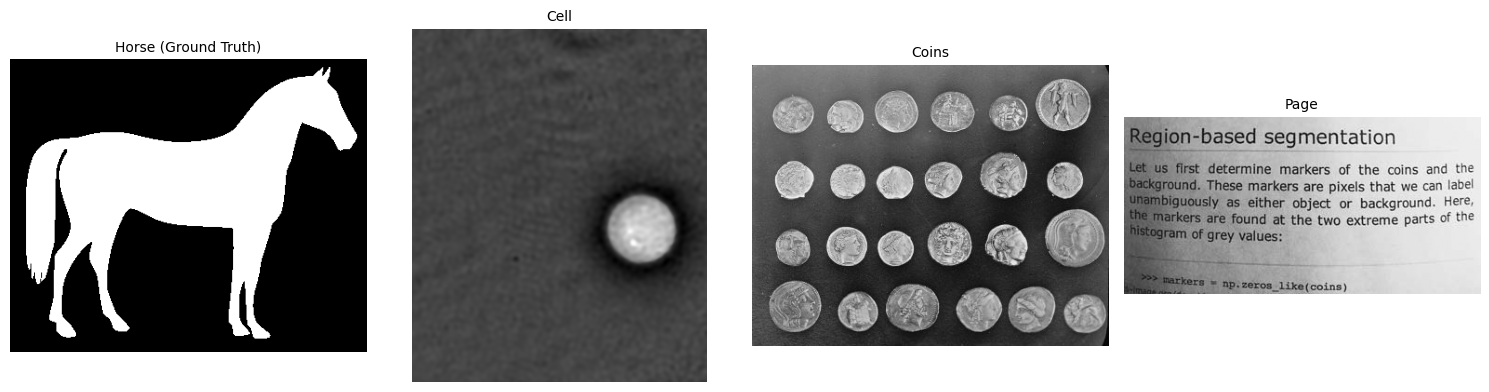

In [21]:
horse_gt = (~data.horse()).astype(np.uint8)
cell_img = to_float(data.cell())
coins_img = to_float(data.coins())
page_img = to_float(data.page())

show([horse_gt, cell_img, coins_img, page_img],
     ['Horse (Ground Truth)', 'Cell', 'Coins', 'Page'])

## 1. Segmentasi Citra `horse` dan Pemrosesan Morfologi

Citra acuan biner `horse` diubah menjadi citra grayscale kemudian diberi gangguan Gaussian noise ($\sigma = 0.12$) serta salt-and-pepper noise (6% piksel). Segmentasi awal dilakukan dengan metode Otsu, lalu dibandingkan hasilnya sebelum dan sesudah diterapkan operasi morfologi menggunakan *structuring element* persegi $3\times3$.

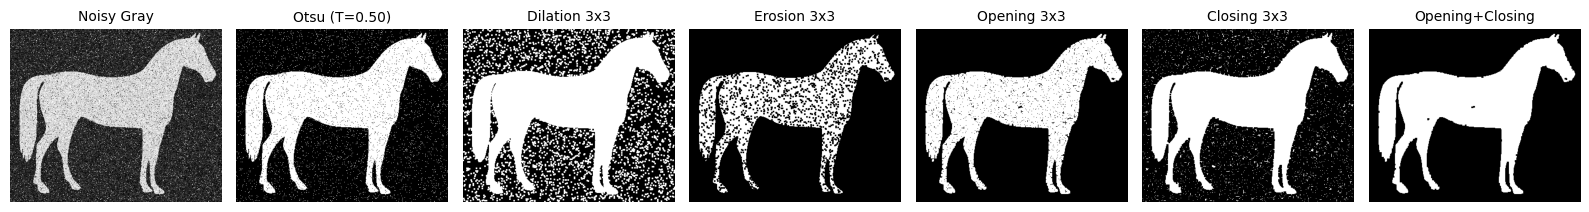

,Accuracy,IoU,Dice (F1)
Tanpa morfologi (Otsu),0.9682,0.9097,0.9527
Dilation (3x3),0.8179,0.6451,0.7842
Erosion (3x3),0.9010,0.7007,0.8240
Opening (3x3),0.9839,0.9514,0.9751
Closing (3x3),0.9702,0.9173,0.9569
Opening + Closing (3x3),0.9963,0.9887,0.9943


In [22]:
def add_degradation(img, sigma=0.12, sp_prob=0.06):
    noisy = np.clip(img + np.random.normal(0, sigma, img.shape), 0.0, 1.0)
    rnd = np.random.rand(*img.shape)
    noisy[rnd < sp_prob / 2] = 0.0
    noisy[rnd > 1.0 - sp_prob / 2] = 1.0
    return noisy

np.random.seed(7)
horse_gray = horse_gt.astype(np.float64) * 0.70 + 0.15
horse_noisy = add_degradation(horse_gray, sigma=0.12, sp_prob=0.06)

seg_horse_otsu, th_horse = otsu_threshold(horse_noisy, foreground='bright')
se_sq3 = get_se('square', 3)

horse_dil = binary_dilation(seg_horse_otsu, se_sq3)
horse_ero = binary_erosion(seg_horse_otsu, se_sq3)
horse_open = binary_opening(seg_horse_otsu, se_sq3)
horse_close = binary_closing(seg_horse_otsu, se_sq3)
horse_open_close = binary_closing(horse_open, se_sq3)

show([horse_noisy, seg_horse_otsu, horse_dil, horse_ero, horse_open, horse_close, horse_open_close],
     ['Noisy Gray', f'Otsu (T={th_horse:.2f})', 'Dilation 3x3', 'Erosion 3x3', 'Opening 3x3', 'Closing 3x3', 'Opening+Closing'],
     figsize=(16, 3.5))

df_horse = pd.DataFrame({
    'Tanpa morfologi (Otsu)': evaluate_seg(horse_gt, seg_horse_otsu),
    'Dilation (3x3)': evaluate_seg(horse_gt, horse_dil),
    'Erosion (3x3)': evaluate_seg(horse_gt, horse_ero),
    'Opening (3x3)': evaluate_seg(horse_gt, horse_open),
    'Closing (3x3)': evaluate_seg(horse_gt, horse_close),
    'Opening + Closing (3x3)': evaluate_seg(horse_gt, horse_open_close),
}).T
df_horse.round(4)

## 2. Segmentasi Citra `cell` dan Pemrosesan Morfologi

Citra `cell` pada kondisi asli memiliki kontras objek sel yang jelas sehingga hasil segmentasi Otsu pada citra asli dapat dijadikan acuan (*ground truth*). Citra kemudian didegradasi dengan Gaussian noise ($\sigma = 0.06$) dan salt-and-pepper noise (4% piksel) untuk menguji kemampuan operasi morfologi dalam mengembalikan bentuk sel.

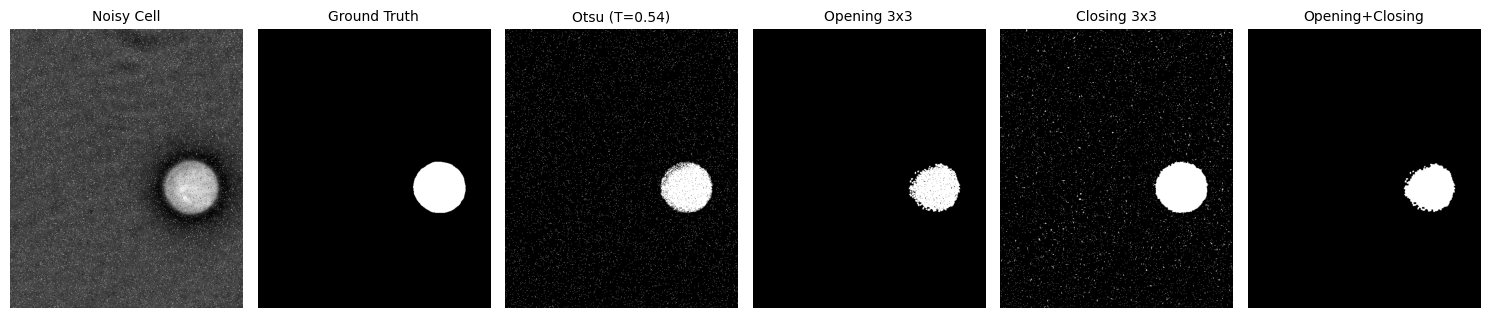

,Accuracy,IoU,Dice (F1)
Tanpa morfologi (Otsu),0.9773,0.5588,0.7169
Dilation (3x3),0.8404,0.1683,0.2882
Erosion (3x3),0.9869,0.5957,0.7466
Opening (3x3),0.9933,0.7945,0.8855
Closing (3x3),0.9773,0.5826,0.7363
Opening + Closing (3x3),0.9945,0.8306,0.9075


In [23]:
np.random.seed(7)
cell_gt, _ = otsu_threshold(cell_img, foreground='bright')
cell_noisy = add_degradation(cell_img, sigma=0.06, sp_prob=0.04)

seg_cell_otsu, th_cell = otsu_threshold(cell_noisy, foreground='bright')

cell_dil = binary_dilation(seg_cell_otsu, se_sq3)
cell_ero = binary_erosion(seg_cell_otsu, se_sq3)
cell_open = binary_opening(seg_cell_otsu, se_sq3)
cell_close = binary_closing(seg_cell_otsu, se_sq3)
cell_open_close = binary_closing(cell_open, se_sq3)

show([cell_noisy, cell_gt, seg_cell_otsu, cell_open, cell_close, cell_open_close],
     ['Noisy Cell', 'Ground Truth', f'Otsu (T={th_cell:.2f})', 'Opening 3x3', 'Closing 3x3', 'Opening+Closing'],
     figsize=(15, 3.5))

df_cell = pd.DataFrame({
    'Tanpa morfologi (Otsu)': evaluate_seg(cell_gt, seg_cell_otsu),
    'Dilation (3x3)': evaluate_seg(cell_gt, cell_dil),
    'Erosion (3x3)': evaluate_seg(cell_gt, cell_ero),
    'Opening (3x3)': evaluate_seg(cell_gt, cell_open),
    'Closing (3x3)': evaluate_seg(cell_gt, cell_close),
    'Opening + Closing (3x3)': evaluate_seg(cell_gt, cell_open_close),
}).T
df_cell.round(4)

## 3. Segmentasi Citra `coins` dan Pengisian Lubang (Hole Filling)

Pada citra `coins`, pencahayaan latar tidak merata dan relief permukaan koin menimbulkan bayangan gelap di bagian dalam koin. Segmentasi dilakukan menggunakan *local mean thresholding* (ukuran jendela $51\times51$) dan dibandingkan dengan Otsu global, kemudian diterapkan operasi *opening* serta *closing* dengan *structuring element* berbentuk *disk* $5\times5$ untuk menutup lubang-lubang pada koin.

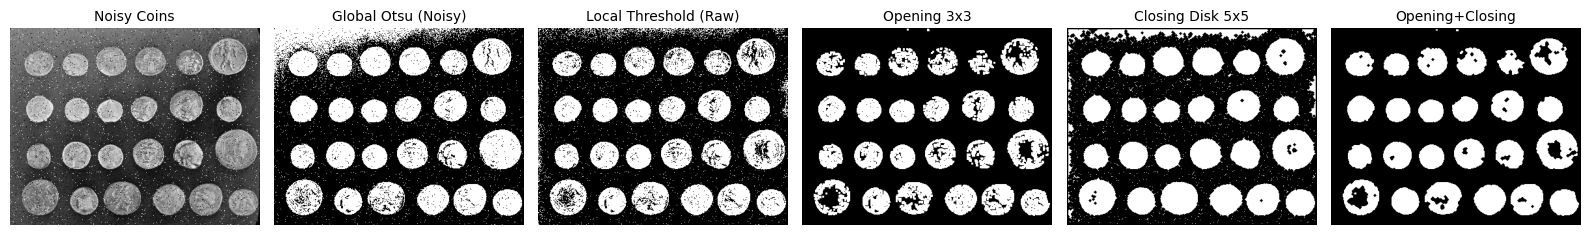

,Accuracy,IoU,Dice (F1)
Global Otsu (Tanpa Morfologi),0.9044,0.7647,0.8667
Local Threshold (Tanpa Morfologi),0.9391,0.8313,0.9079
Local + Opening (3x3),0.9383,0.8152,0.8982
Local + Closing (Disk 5x5),0.9494,0.8676,0.9291
Local + Opening & Closing,0.9667,0.9004,0.9476


In [24]:
se_disk5 = get_se('disk', 5)

seg_coins_local = local_mean_threshold(coins_img, win_size=51, offset=0.04, foreground='bright')

# Ground truth koin bersih diperoleh dari penutupan lubang dan pembersihan latar pada segmentasi lokal
coins_gt = binary_opening(binary_closing(seg_coins_local, se_disk5), se_sq3)

# Simulasi gangguan bintik noise pada citra coins
np.random.seed(7)
coins_noisy = add_degradation(coins_img, sigma=0.03, sp_prob=0.03)

# Kedua metode segmentasi diterapkan pada citra noisy yang sama
seg_coins_otsu, th_coins = otsu_threshold(coins_noisy, foreground='bright')
seg_coins_noisy = local_mean_threshold(coins_noisy, win_size=51, offset=0.04, foreground='bright')

coins_open = binary_opening(seg_coins_noisy, se_sq3)
coins_close = binary_closing(seg_coins_noisy, se_disk5)
coins_open_close = binary_closing(coins_open, se_disk5)

show([coins_noisy, seg_coins_otsu, seg_coins_noisy, coins_open, coins_close, coins_open_close],
     ['Noisy Coins', 'Global Otsu (Noisy)', 'Local Threshold (Raw)', 'Opening 3x3', 'Closing Disk 5x5', 'Opening+Closing'],
     figsize=(16, 3.5))

df_coins = pd.DataFrame({
    'Global Otsu (Tanpa Morfologi)': evaluate_seg(coins_gt, seg_coins_otsu),
    'Local Threshold (Tanpa Morfologi)': evaluate_seg(coins_gt, seg_coins_noisy),
    'Local + Opening (3x3)': evaluate_seg(coins_gt, coins_open),
    'Local + Closing (Disk 5x5)': evaluate_seg(coins_gt, coins_close),
    'Local + Opening & Closing': evaluate_seg(coins_gt, coins_open_close),
}).T
df_coins.round(4)

## 4. Perbaikan Karakter Teks Terputus pada Citra `page`

Mengacu pada contoh aplikasi morfologi di materi kuliah, teks dengan resolusi rendah atau terdegradasi sering mengalami patahan pada bagian huruf. Potongan citra `page` disegmentasi lalu disimulasikan mengalami keretakan piksel (dropout), kemudian diperbaiki menggunakan *dilation* dan *closing* dengan *structuring element* berbentuk palang (*cross* $3\times3$).

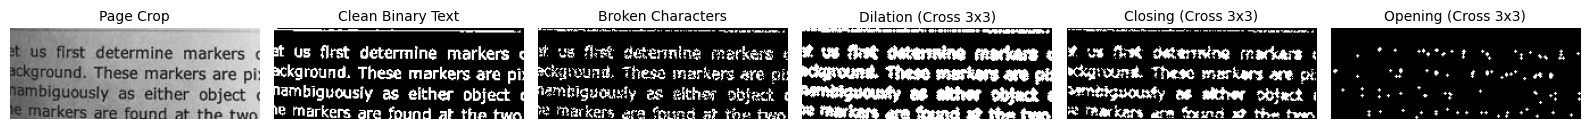

,Accuracy,IoU,Dice (F1)
Teks Terputus (Tanpa Morfologi),0.9501,0.7758,0.8738
Dilation (Cross 3x3),0.8294,0.5645,0.7216
Closing (Cross 3x3),0.9278,0.7188,0.8364
Opening (Cross 3x3),0.8074,0.1357,0.2389


In [25]:
page_crop = page_img[35:115, 15:235]
page_gt = local_mean_threshold(page_crop, win_size=25, offset=0.05, foreground='dark')

# Simulasi karakter patah/retak (random foreground dropout)
np.random.seed(7)
dropout_mask = (np.random.rand(*page_gt.shape) > 0.22).astype(np.uint8)
page_broken = page_gt & dropout_mask

se_cross3 = get_se('cross', 3)
page_dil = binary_dilation(page_broken, se_cross3)
page_close = binary_closing(page_broken, se_cross3)
page_open = binary_opening(page_broken, se_cross3)

show([page_crop, page_gt, page_broken, page_dil, page_close, page_open],
     ['Page Crop', 'Clean Binary Text', 'Broken Characters', 'Dilation (Cross 3x3)', 'Closing (Cross 3x3)', 'Opening (Cross 3x3)'],
     figsize=(16, 3))

df_page = pd.DataFrame({
    'Teks Terputus (Tanpa Morfologi)': evaluate_seg(page_gt, page_broken),
    'Dilation (Cross 3x3)': evaluate_seg(page_gt, page_dil),
    'Closing (Cross 3x3)': evaluate_seg(page_gt, page_close),
    'Opening (Cross 3x3)': evaluate_seg(page_gt, page_open),
}).T
df_page.round(4)

## 5. Operasi Morfologi Lanjutan: Edge Detection, Thinning, dan Skeletonization

Operasi morfologi turunan dan lanjutan diuji pada hasil segmentasi `horse` untuk melihat perbedaan ekstraksi tepi (*morphological gradient* / *edge detection*) serta penipisan kerangka objek (*thinning* dan *skeletonization*) antara citra hasil segmentasi yang belum diproses morfologi dan yang sudah dibersihkan dengan *opening-closing*.

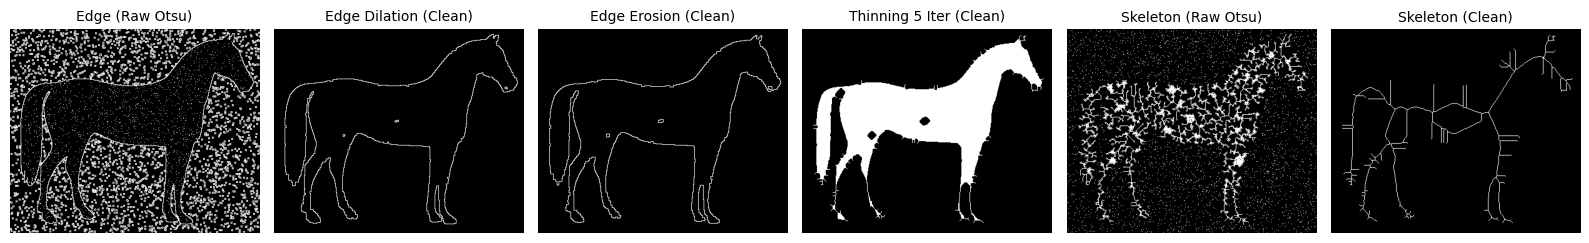

In [26]:
# Edge detection pada hasil segmentasi tanpa morfologi vs setelah Opening+Closing
edge_raw_dil = binary_dilation(seg_horse_otsu, se_sq3) & (~seg_horse_otsu)
edge_clean_dil = binary_dilation(horse_open_close, se_sq3) & (~horse_open_close)
edge_clean_ero = horse_open_close & (~binary_erosion(horse_open_close, se_sq3))

# Thinning (5 iterasi) dan Skeletonization penuh
thin_clean = binary_thinning(horse_open_close, iterations=5)
skel_raw = binary_skeletonize(seg_horse_otsu, max_iter=100)
skel_clean = binary_skeletonize(horse_open_close, max_iter=100)
show([edge_raw_dil, edge_clean_dil, edge_clean_ero, thin_clean, skel_raw, skel_clean],
     ['Edge (Raw Otsu)', 'Edge Dilation (Clean)', 'Edge Erosion (Clean)', 'Thinning 5 Iter (Clean)', 'Skeleton (Raw Otsu)', 'Skeleton (Clean)'],
     figsize=(16, 3.5))